Load Fashion-MNIST, prepare data loaders, select a device, and display sample images.

100.0%
100.0%
100.0%
100.0%


Device: cpu
One training batch tensor shape: (64, 1, 28, 28)
Class names: ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']


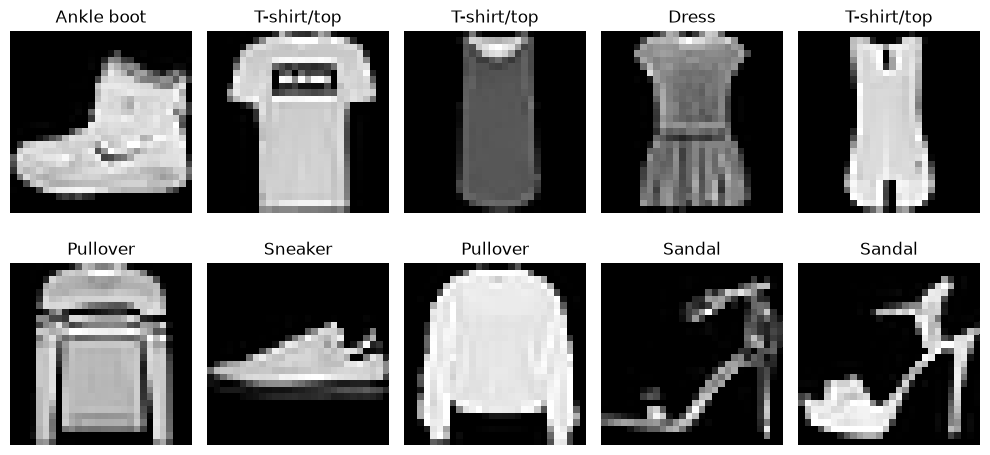

In [1]:
from pathlib import Path
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

class_names = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot",
]

project_root = Path.cwd()
while project_root != project_root.parent and not (project_root / ".venv").is_dir():
    project_root = project_root.parent
if not (project_root / ".venv").is_dir():
    raise FileNotFoundError("Could not find the project root containing .venv")
data_dir = project_root / "data"
data_dir.mkdir(parents=True, exist_ok=True)

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.2860,), (0.3530,)),
])
train_dataset = datasets.FashionMNIST(root=data_dir, train=True, download=True, transform=transform)
test_dataset = datasets.FashionMNIST(root=data_dir, train=False, download=True, transform=transform)
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=256, shuffle=False)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
images, labels = next(iter(train_loader))
print("One training batch tensor shape:", tuple(images.shape))
print("Class names:", class_names)

fig, axes = plt.subplots(2, 5, figsize=(10, 5))
for index, axis in enumerate(axes.flat):
    image = train_dataset[index][0].squeeze(0) * 0.3530 + 0.2860
    label = train_dataset[index][1]
    axis.imshow(image, cmap="gray")
    axis.set_title(class_names[label])
    axis.axis("off")
fig.tight_layout()
plt.show()

Define the MLP and CNN, count their trainable parameters, and inspect each CNN layer's output shape.

In [2]:
class SmallCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Flatten(),
            nn.Linear(32 * 7 * 7, 10),
        )

    def forward(self, inputs):
        return self.layers(inputs)

def build_mlp():
    return nn.Sequential(
        nn.Flatten(),
        nn.Linear(784, 128),
        nn.ReLU(),
        nn.Linear(128, 10),
    )

def count_trainable_parameters(model):
    return sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad)

mlp = build_mlp().to(device)
cnn = SmallCNN().to(device)
print("MLP trainable parameters:", count_trainable_parameters(mlp))
print("CNN trainable parameters:", count_trainable_parameters(cnn))

dummy = torch.zeros(1, 1, 28, 28, device=device)
print("CNN layer output shapes:")
with torch.no_grad():
    layer_output = dummy
    for layer in cnn.layers:
        layer_output = layer(layer_output)
        print(f"{layer.__class__.__name__}: {tuple(layer_output.shape)}")

MLP trainable parameters: 101770
CNN trainable parameters: 20490
CNN layer output shapes:
Conv2d: (1, 16, 28, 28)
ReLU: (1, 16, 28, 28)
MaxPool2d: (1, 16, 14, 14)
Conv2d: (1, 32, 14, 14)
ReLU: (1, 32, 14, 14)
MaxPool2d: (1, 32, 7, 7)
Flatten: (1, 1568)
Linear: (1, 10)


Train each model for five epochs and record training loss, test accuracy, and epoch time.

In [3]:
def train_one_epoch(model, loader, loss_fn, opt):
    model.train()
    total_loss = 0.0
    total_examples = 0
    for batch_images, batch_labels in loader:
        batch_images = batch_images.to(device)
        batch_labels = batch_labels.to(device)
        predictions = model(batch_images)
        loss = loss_fn(predictions, batch_labels)
        opt.zero_grad()
        loss.backward()
        opt.step()
        total_loss += loss.item() * batch_labels.size(0)
        total_examples += batch_labels.size(0)
    return total_loss / total_examples

def evaluate(model, loader):
    model.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for batch_images, batch_labels in loader:
            batch_images = batch_images.to(device)
            batch_labels = batch_labels.to(device)
            predictions = model(batch_images).argmax(dim=1)
            correct += (predictions == batch_labels).sum().item()
            total += batch_labels.size(0)
    return correct / total

torch.manual_seed(42)
torch.set_num_threads(min(4, torch.get_num_threads()))
models = {"MLP": mlp, "CNN": cnn}
history = {name: [] for name in models}
training_totals = {}
loss_fn = nn.CrossEntropyLoss()

for model_name, model in models.items():
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    total_training_time = 0.0
    print(f"\nTraining {model_name}")
    for epoch in range(1, 6):
        epoch_start = time.perf_counter()
        train_loss = train_one_epoch(model, train_loader, loss_fn, optimizer)
        test_accuracy = evaluate(model, test_loader)
        epoch_time = time.perf_counter() - epoch_start
        total_training_time += epoch_time
        history[model_name].append({
            "epoch": epoch,
            "train_loss": train_loss,
            "test_accuracy": test_accuracy,
            "epoch_time_seconds": epoch_time,
        })
        print(f"Epoch {epoch}/5: train loss={train_loss:.4f}, test accuracy={test_accuracy:.4f}, time={epoch_time:.2f}s")
    training_totals[model_name] = total_training_time

epoch_results = pd.DataFrame([
    {"Model": model_name, **row}
    for model_name, rows in history.items()
    for row in rows
])
print("\nPer-epoch results:")
print(epoch_results.to_string(index=False, formatters={
    "train_loss": "{:.4f}".format,
    "test_accuracy": "{:.4f}".format,
    "epoch_time_seconds": "{:.2f}".format,
}))


Training MLP
Epoch 1/5: train loss=0.4674, test accuracy=0.8499, time=16.87s
Epoch 2/5: train loss=0.3545, test accuracy=0.8622, time=17.34s
Epoch 3/5: train loss=0.3213, test accuracy=0.8693, time=16.38s
Epoch 4/5: train loss=0.2950, test accuracy=0.8758, time=16.75s
Epoch 5/5: train loss=0.2787, test accuracy=0.8747, time=16.63s

Training CNN
Epoch 1/5: train loss=0.4540, test accuracy=0.8710, time=32.99s
Epoch 2/5: train loss=0.3117, test accuracy=0.8927, time=34.07s
Epoch 3/5: train loss=0.2704, test accuracy=0.8984, time=32.07s
Epoch 4/5: train loss=0.2472, test accuracy=0.9021, time=32.13s
Epoch 5/5: train loss=0.2286, test accuracy=0.9007, time=34.16s

Per-epoch results:
Model  epoch train_loss test_accuracy epoch_time_seconds
  MLP      1     0.4674        0.8499              16.87
  MLP      2     0.3545        0.8622              17.34
  MLP      3     0.3213        0.8693              16.38
  MLP      4     0.2950        0.8758              16.75
  MLP      5     0.2787    

Plot test accuracy by epoch for both the MLP and CNN.

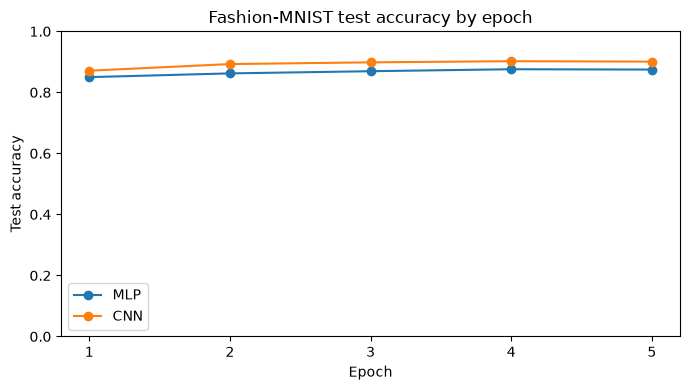

In [4]:
plt.figure(figsize=(7, 4))
for model_name in models:
    model_history = history[model_name]
    plt.plot(
        [row["epoch"] for row in model_history],
        [row["test_accuracy"] for row in model_history],
        marker="o",
        label=model_name,
    )
plt.xlabel("Epoch")
plt.ylabel("Test accuracy")
plt.title("Fashion-MNIST test accuracy by epoch")
plt.xticks(range(1, 6))
plt.ylim(0, 1)
plt.legend()
plt.tight_layout()
plt.show()

Evaluate the CNN by class and display its confusion matrix with Fashion-MNIST class names.

              precision    recall  f1-score   support

 T-shirt/top       0.90      0.80      0.85      1000
     Trouser       1.00      0.96      0.98      1000
    Pullover       0.85      0.86      0.86      1000
       Dress       0.90      0.90      0.90      1000
        Coat       0.78      0.93      0.85      1000
      Sandal       0.98      0.99      0.98      1000
       Shirt       0.75      0.67      0.71      1000
     Sneaker       0.98      0.92      0.95      1000
         Bag       0.95      0.99      0.97      1000
  Ankle boot       0.94      0.98      0.96      1000

    accuracy                           0.90     10000
   macro avg       0.90      0.90      0.90     10000
weighted avg       0.90      0.90      0.90     10000



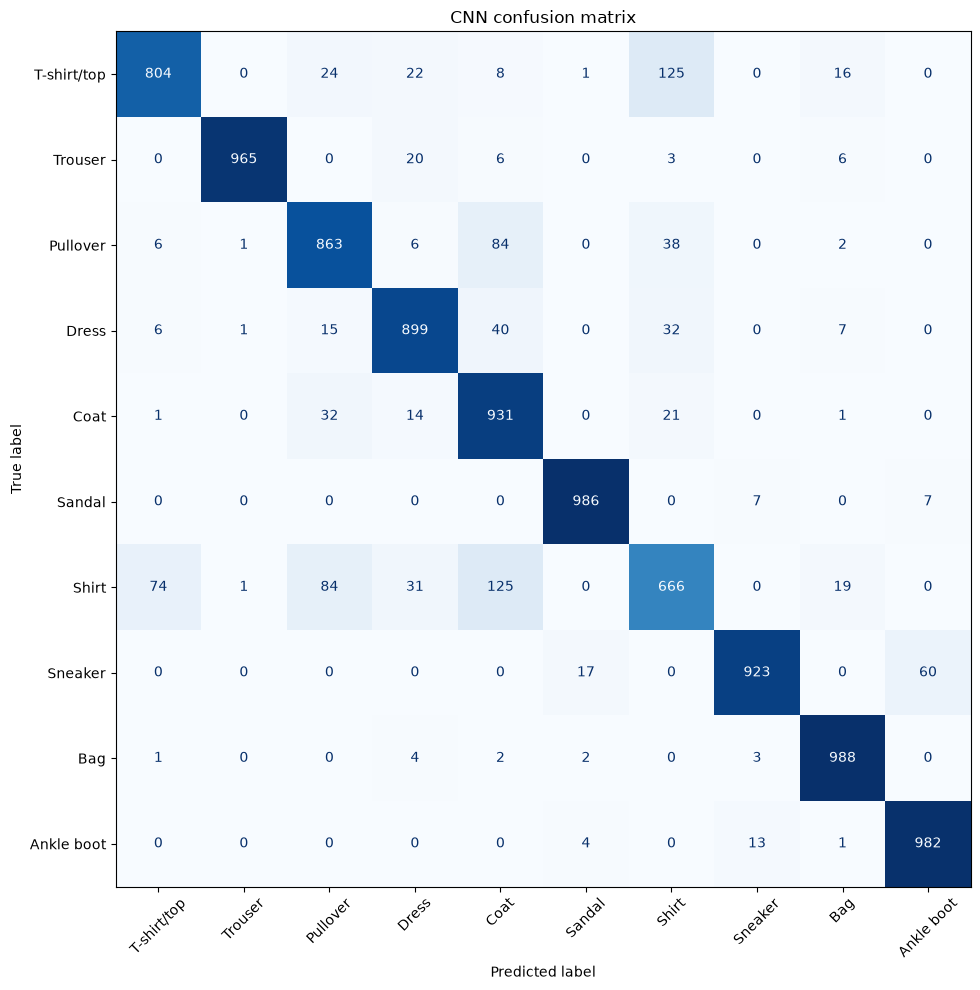

In [5]:
cnn.eval()
cnn_true = []
cnn_predicted = []
with torch.no_grad():
    for batch_images, batch_labels in test_loader:
        logits = cnn(batch_images.to(device))
        cnn_predicted.extend(logits.argmax(dim=1).cpu().tolist())
        cnn_true.extend(batch_labels.tolist())

print(classification_report(
    cnn_true,
    cnn_predicted,
    labels=list(range(len(class_names))),
    target_names=class_names,
    zero_division=0,
))
cnn_confusion = confusion_matrix(cnn_true, cnn_predicted, labels=list(range(len(class_names))))
display = ConfusionMatrixDisplay(confusion_matrix=cnn_confusion, display_labels=class_names)
fig, ax = plt.subplots(figsize=(10, 10))
display.plot(ax=ax, cmap="Blues", xticks_rotation=45, colorbar=False)
ax.set_title("CNN confusion matrix")
fig.tight_layout()
plt.show()

Show up to 10 Fashion-MNIST test images that the CNN classified incorrectly.

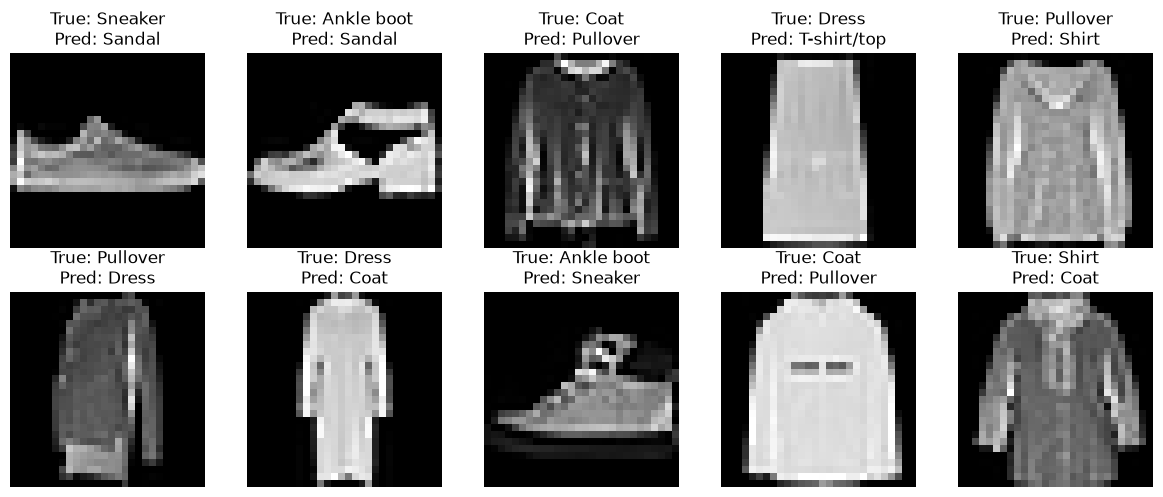

Misclassified test images displayed: 10


In [6]:
misclassified_indices = [
    index for index, (truth, prediction) in enumerate(zip(cnn_true, cnn_predicted))
    if truth != prediction
][:10]
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for axis, index in zip(axes.flat, misclassified_indices):
    image, true_label = test_dataset[index]
    axis.imshow(image.squeeze(0) * 0.3530 + 0.2860, cmap="gray")
    axis.set_title(f"True: {class_names[true_label]}\nPred: {class_names[cnn_predicted[index]]}")
    axis.axis("off")
for axis in axes.flat[len(misclassified_indices):]:
    axis.axis("off")
fig.tight_layout()
plt.show()
print("Misclassified test images displayed:", len(misclassified_indices))

Save and reload the CNN weights, verify accuracy is unchanged, and compare the two models.

In [7]:
models_dir = project_root / "models"
models_dir.mkdir(parents=True, exist_ok=True)
model_path = models_dir / "small_cnn_fashionmnist.pth"
accuracy_before_save = evaluate(cnn, test_loader)
torch.save(cnn.state_dict(), model_path)

reloaded_cnn = SmallCNN().to(device)
reloaded_cnn.load_state_dict(torch.load(model_path, map_location=device, weights_only=True))
accuracy_after_reload = evaluate(reloaded_cnn, test_loader)
print("Saved CNN weights to:", model_path)
print(f"CNN accuracy before save: {accuracy_before_save:.4f}")
print(f"CNN accuracy after reload: {accuracy_after_reload:.4f}")
assert np.isclose(accuracy_before_save, accuracy_after_reload)
print("Reloaded CNN accuracy matches.")

summary_rows = []
for model_name, model in models.items():
    summary_rows.append({
        "Model": model_name,
        "Parameters": count_trainable_parameters(model),
        "Final test accuracy": evaluate(model, test_loader),
        "Total training time (seconds)": training_totals[model_name],
    })
summary = pd.DataFrame(summary_rows)
print("\nModel comparison:")
print(summary.to_string(index=False, formatters={
    "Final test accuracy": "{:.4f}".format,
    "Total training time (seconds)": "{:.2f}".format,
}))

Saved CNN weights to: c:\Users\User\Deepfake-Blockchain-Project\models\small_cnn_fashionmnist.pth
CNN accuracy before save: 0.9007
CNN accuracy after reload: 0.9007
Reloaded CNN accuracy matches.

Model comparison:
Model  Parameters Final test accuracy Total training time (seconds)
  MLP      101770              0.8747                         83.97
  CNN       20490              0.9007                        165.43
